# Baseball Arm Injuries: Tommy John Surgery Trends and Recovery

Final Project — Checkpoint #2
Topic: Arm injuries in baseball, focused on Tommy John surgery (ulnar collateral ligament reconstruction).

### Research question
How have documented Tommy John surgeries changed over time, and how do age, position, throwing hand, and level of play relate to the characteristics and documented recovery times of these cases?

 Scope: This dataset contains surgery cases, not every baseball player. It can describe reported surgeries and recovery among documented cases, but cannot estimate injury risk or prove which characteristics cause injuries without a comparison population.

Project continuity: Keep the Checkpoint #1 problem statement and dataset discussion in your existing `source.ipynb`. If your original research question differs, revise this wording to match your earlier work. The sections below fulfill Checkpoint #2.

## Data Sources

Primary source: [Jon Roegele's Tommy John Surgery List](https://docs.google.com/spreadsheets/d/1gQujXQQGOVNaiuwSN680Hq-FDVsCwvN-3AazykOBON0/edit). This public spreadsheet documents reported surgeries and fields including player, surgery date, competition level, position, handedness, age, and return/recovery information where known.

Backup snapshot: [Archived Tommy John surgery CSV on GitHub](https://github.com/derrickvasquez/Tommy-John-Surgery-Analysis/blob/Main/Updated%20Tommy%20John%20Surgery%20List%20%28%40MLBPlayerAnalys%29.csv). The backup may be older than the live list.

The notebook downloads the primary dataset the first time you run it, or uses a copy at `data/tj_surgeries.csv` if one already exists. Commit that actual CSV file to your GitHub repository so peer reviewers can reproduce the analysis without relying on a live download. Record the access date and whether the primary or archived data was used. The published list evolves over time.

Dataset limitation: This represents reported surgeries rather than all arm injuries (e.g., shoulder and flexor injuries are outside the scope). Earlier time periods may be less completely documented, and 2026 is an incomplete calendar year.

## 1. Exploratory Data Analysis (EDA)


In [1]:
from pathlib import Path
from io import StringIO
import csv
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 25)
print("pandas:", pd.__version__)

pandas: 2.2.3


In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "tj_surgeries.csv"
PRIMARY_URL = ("https://docs.google.com/spreadsheets/d/"
               "1gQujXQQGOVNaiuwSN680Hq-FDVsCwvN-3AazykOBON0/export?format=csv&gid=0")
BACKUP_URL = ("https://raw.githubusercontent.com/derrickvasquez/"
              "Tommy-John-Surgery-Analysis/Main/"
              "Updated%20Tommy%20John%20Surgery%20List%20%28%40MLBPlayerAnalys%29.csv")

def has_expected_header(csv_text):
    first_rows = list(csv.reader(StringIO(csv_text)))[:35]
    return any("Player" in row and "TJ Surgery Date" in row for row in first_rows)

if not DATA_PATH.exists():
    failures = []
    for label, url in [("Jon Roegele live spreadsheet", PRIMARY_URL),
                       ("archived GitHub snapshot", BACKUP_URL)]:
        try:
            response = requests.get(url, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
            response.raise_for_status()
            response.encoding = "utf-8-sig"
            if not has_expected_header(response.text):
                raise ValueError("Downloaded file did not contain the expected headers")
            DATA_PATH.write_text(response.text, encoding="utf-8")
            print(f"Downloaded {label} to {DATA_PATH}")
            break
        except (requests.RequestException, ValueError) as exc:
            failures.append(f"{label}: {exc}")
    else:
        raise RuntimeError(
            "Automatic download failed. Open the primary spreadsheet's 'TJ List' "
            "tab, select File > Download > Comma Separated Values (.csv), "
            "save it as data/tj_surgeries.csv, then rerun. Details: " + "; ".join(failures)
        )
else:
    print(f"Using existing CSV: {DATA_PATH} (commit this file for reviewers)")

Downloaded Jon Roegele live spreadsheet to data\tj_surgeries.csv


In [14]:
def load_raw_surgery_list(path):
    with open(path, encoding="utf-8-sig", newline="") as handle:
        rows = list(csv.reader(handle))
    header_index = next((i for i, row in enumerate(rows[:35])
                         if "Player" in row and "TJ Surgery Date" in row), None)
    if header_index is None:
        raise ValueError("Could not find columns 'Player' and 'TJ Surgery Date'")
    headers = [col.strip() for col in rows[header_index]]
    n = len(headers)
    records = [(row[:n] + [""] * max(0, n - len(row))) for row in rows[header_index + 1:]
               if any(value.strip() for value in row)]
    df = pd.DataFrame(records, columns=headers)
    df = df.loc[:, ~pd.Index(df.columns).duplicated()].copy()
    df = df.loc[:, [bool(col.strip()) for col in df.columns]].copy()
    df = df.replace(r"^\s*$", np.nan, regex=True)
    df = df.loc[df["Player"].notna()].copy()
    df = df.loc[~df["Player"].astype(str).str.contains(
        "THE TOMMY JOHN SURGERY LIST HAS MOVED", case=False, na=False)].copy()
    df = df.reset_index(drop=True)
    return df

raw = load_raw_surgery_list(DATA_PATH)
print(f"Rows: {len(raw):,}; columns: {len(raw.columns)}")
display(raw.head())
print("Original dtypes:")
display(raw.dtypes.rename("dtype").to_frame())

Rows: 2,745; columns: 34


,Player,TJ Surgery Date,Team,Level,Position,Throws,Country,High School,College(s),Age,Return Date (same level),Recovery Time (months),...,Mound,Bullpen,Live\r\nHitters,Game,Setback,Setback Type,G,GS,IP,K-BB%,ERA-,FIP-
0,Carson Whisenhunt,9/16/2026,SF,MLB,P,L,United States,North Carolina,East Carolina,25,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Hunter Dobbins,9/2/2026,STL,MLB,P,R,United States,Texas,Texas Tech,26,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Hurston Waldrep,9/1/2026,ATL,MLB,P,R,United States,Georgia,"Florida, Southern Mississippi",24,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Nick Raquet,9/1/2026,BAL,AAA,P,L,United States,Pennsylvania,"William and Mary, North Carolina",30,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Jordan Leasure,8/17/2026,CHW,MLB,P,R,United States,Florida,Tampa,27,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Original dtypes:


,dtype
Player,object
TJ Surgery Date,object
Team,object
Level,object
Position,object
Throws,object
Country,object
High School,object
College(s),object
Age,object


In [15]:
print("Raw missing values (top 15):")
missing = raw.isna().sum().sort_values(ascending=False)
missing_pct = raw.isna().mean().mul(100).round(1)
display(pd.DataFrame({"Missing": missing, "Missing %": missing_pct}).head(15))
print("Entirely duplicated rows:", int(raw.duplicated().sum()))

column_mapping = {
    "Player": "player", "TJ Surgery Date": "surgery_date", "Team": "team",
    "Level": "level", "Majors": "level", "Position": "position",
    "Throws": "throws", "Age": "age", "Return Date (same level)": "return_date",
    "Recovery Time (months)": "recovery_months", "Country": "country",
    "mlbamid": "mlbamid", "Surgeon(s)": "surgeons"
}
eda = raw.rename(columns=column_mapping).copy()
if eda.columns.duplicated().any():
    eda = eda.loc[:, ~eda.columns.duplicated()].copy()
for field in ["player", "surgery_date", "level", "position", "throws", "age",
              "recovery_months", "return_date", "mlbamid"]:
    if field not in eda:
        eda[field] = pd.NA

eda["surgery_date"] = pd.to_datetime(eda["surgery_date"], errors="coerce")
eda["return_date"] = pd.to_datetime(eda["return_date"], errors="coerce")
eda["age"] = pd.to_numeric(eda["age"], errors="coerce")
eda["recovery_months"] = pd.to_numeric(eda["recovery_months"], errors="coerce")
eda["surgery_year"] = eda["surgery_date"].dt.year
eda["player_key"] = eda["player"].astype("string").str.strip().str.casefold()
print("Same player + surgery date repeated:", int(eda.duplicated(["player_key", "surgery_date"]).sum()))
print("Surgery dates that could not be parsed:", int(eda["surgery_date"].isna().sum()))
print("Ages outside plausible 12–60 range:", int(((eda["age"] < 12) | (eda["age"] > 60)).sum()))
print("Nonpositive recovery times:", int((eda["recovery_months"] <= 0).sum()))
print("Recovery times over 60 months (review, not automatically an error):",
      int((eda["recovery_months"] > 60).sum()))

Raw missing values (top 15):


,Missing,Missing %
Active,0,0.0
Age,0,0.0
Bullpen,2698,98.3
College(s),1049,38.2
Country,0,0.0
Day,0,0.0
ERA-,2686,97.9
FIP-,2686,97.9
G,2686,97.9
GS,2686,97.9


Entirely duplicated rows: 0
Same player + surgery date repeated: 0
Surgery dates that could not be parsed: 0
Ages outside plausible 12–60 range: 0
Nonpositive recovery times: 0
Recovery times over 60 months (review, not automatically an error): 3


### EDA: Distributions, relationships, and potential issues

The raw inspections above identify fields with missing information, possible duplicate surgery events, and values that require numeric/date conversion. A surgery event is identified by player and date, not player alone: one player may undergo multiple procedures. Plots below describe reported case counts, which are not injury rates.

Graph 1: Surgery counts over time - Shows recorded surgery events by calendar year (2000–2025). We intentionally exclude 2026 because it is incomplete, and should not compare a partial year with full years.

Highest observed annual count (2000–2025): 2021 (176 cases)


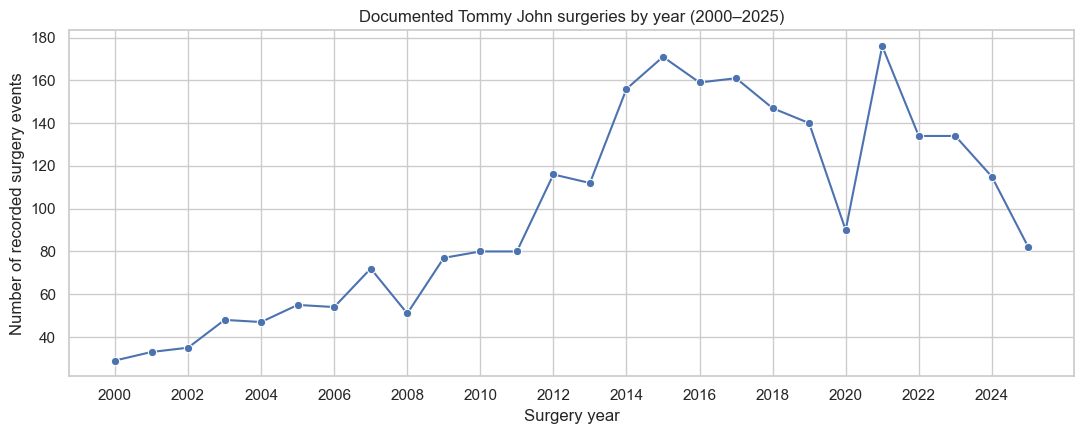

In [5]:
annual_counts = (eda.loc[eda["surgery_year"].between(2000, 2025), "surgery_year"]
                   .value_counts().sort_index())
fig, ax = plt.subplots(figsize=(11, 4.5))
if len(annual_counts):
    sns.lineplot(x=annual_counts.index.astype(int), y=annual_counts.values,
                 marker="o", ax=ax)
    ax.set_xticks(list(range(2000, 2026, 2)))
    peak_year = int(annual_counts.idxmax())
    print(f"Highest observed annual count (2000–2025): {peak_year} ({annual_counts.max()} cases)")
else:
    ax.text(.5, .5, "No cases in 2000–2025", ha="center", va="center", transform=ax.transAxes)
ax.set(title="Documented Tommy John surgeries by year (2000–2025)",
       xlabel="Surgery year", ylabel="Number of recorded surgery events")
plt.tight_layout()
plt.show()

Interpretation: This graph reveals changes in the number of recorded cases. In the final write-up, identify the peak year from the output. The rise or fall cannot automatically be interpreted as a change in individual injury risk because baseball population size and reporting completeness may also change.

Graph 2 — Age distribution:A histogram of ages at the time of surgery. Ages outside 12–60 are hidden from the plot for readability and separately flagged for investigation; they are not silently removed from the raw dataset.

Median documented age at surgery: 23.0 years; n=2,745


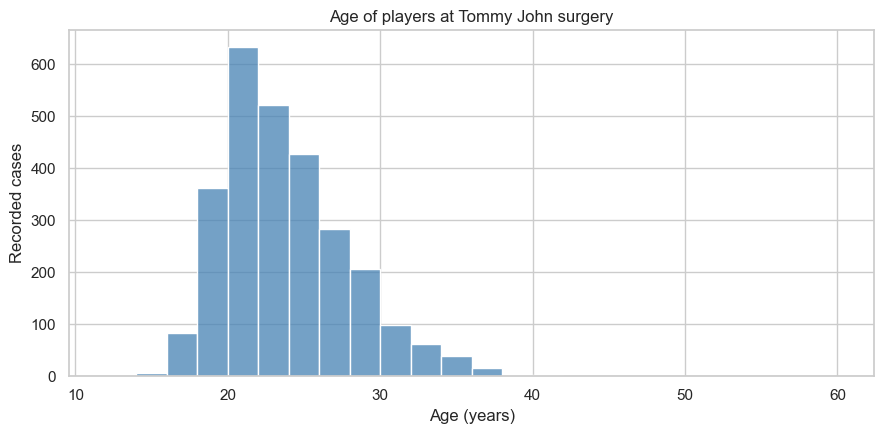

In [6]:
age_plot = eda["age"].dropna().loc[lambda s: s.between(12, 60)]
fig, ax = plt.subplots(figsize=(9, 4.5))
if not age_plot.empty:
    sns.histplot(age_plot, bins=range(12, 62, 2), color="steelblue", ax=ax)
    print(f"Median documented age at surgery: {age_plot.median():.1f} years; n={len(age_plot):,}")
else:
    ax.text(.5, .5, "No valid numeric ages", ha="center", transform=ax.transAxes)
ax.set(title="Age of players at Tommy John surgery", xlabel="Age (years)", ylabel="Recorded cases")
plt.tight_layout()
plt.show()

Interpretation: The histogram shows which age ranges account for the largest counts of surgeries in the dataset. It does not establish age-specific injury risk without counts of all players of each age.

Graph 3 — Playing level: Compares recorded cases across levels of competition, such as MLB and minor-league levels. Differences may partly reflect how many athletes participate at each level.

Most frequently reported playing level: MLB (702 cases)


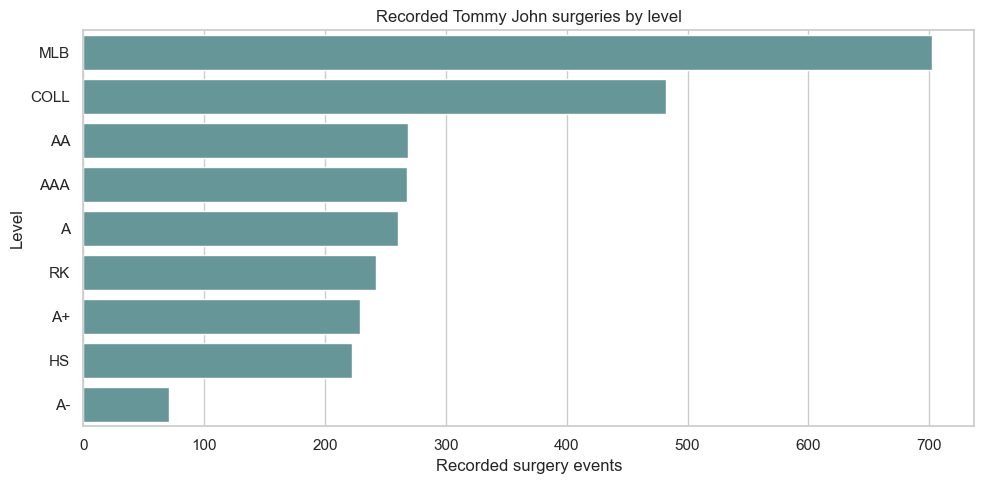

In [7]:
level_counts = (eda["level"].astype("string").str.strip().str.upper()
                .replace({"": pd.NA}).dropna().value_counts().head(12))
fig, ax = plt.subplots(figsize=(10, 5))
if len(level_counts):
    sns.barplot(x=level_counts.values, y=level_counts.index, ax=ax, color="cadetblue")
    print("Most frequently reported playing level:", level_counts.index[0],
          f"({int(level_counts.iloc[0])} cases)")
else:
    ax.text(.5, .5, "No documented levels", ha="center", transform=ax.transAxes)
ax.set(title="Recorded Tommy John surgeries by level", xlabel="Recorded surgery events", ylabel="Level")
plt.tight_layout()
plt.show()

Interpretation: This plot describes the dataset's composition across levels, not how dangerous each level is. Different levels have different population sizes and reporting coverage.

Graph 4 — Recovery time vs. age: A scatterplot shows the relationship between a player's recorded age and the reported months needed to return to the **same level**, among players for whom both measurements are known. Missing recovery values are excluded only from this plot; they do not mean zero recovery or failure to return.

Cases with known age and recovery: 1,382
Spearman correlation (age vs recovery time): -0.004


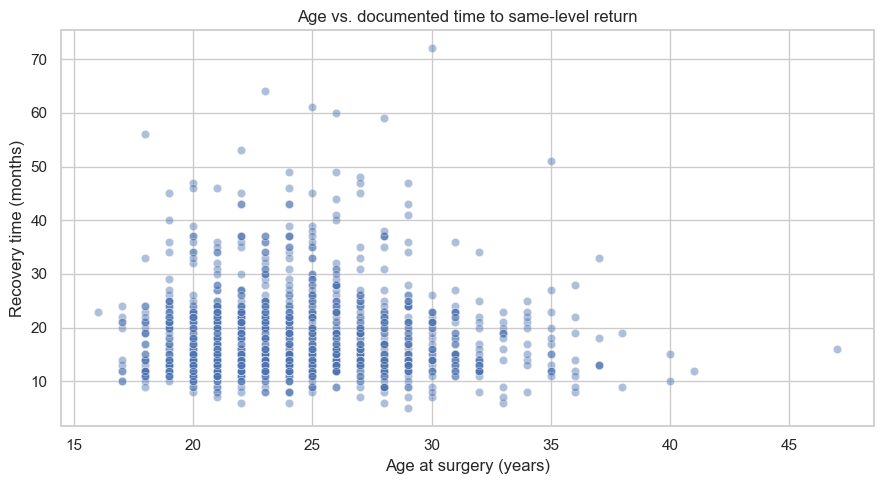

In [8]:
recovery_plot = eda.loc[
    eda["age"].between(12, 60) & eda["recovery_months"].gt(0),
    ["age", "recovery_months"]
].dropna().copy()
fig, ax = plt.subplots(figsize=(9, 5))
if not recovery_plot.empty:
    sns.scatterplot(data=recovery_plot, x="age", y="recovery_months", alpha=.45, ax=ax)
    print(f"Cases with known age and recovery: {len(recovery_plot):,}")
    if len(recovery_plot) >= 3 and recovery_plot["age"].nunique() > 1 and recovery_plot["recovery_months"].nunique() > 1:
        print("Spearman correlation (age vs recovery time):",
              round(recovery_plot["age"].corr(recovery_plot["recovery_months"], method="spearman"), 3))
else:
    ax.text(.5, .5, "Recovery values are unavailable", ha="center", transform=ax.transAxes)
ax.set(title="Age vs. documented time to same-level return",
       xlabel="Age at surgery (years)", ylabel="Recovery time (months)")
plt.tight_layout()
plt.show()

Interpretation: This plot tests for a possible *association* between age and recorded time to return. Even if a correlation appears, it does not show that age causes the difference: playing level, severity, rehab protocols, and selection of players with known return dates may contribute. Surgeries from recent years have not had equal follow-up time.

Graph 5 — Throwing hand: Compares how many recorded surgery cases involve left-handed and right-handed throwers. Percentages are of *surgery cases*, not of the full baseball population.

Among recorded R/L surgery cases: R=76.6%, L=23.4%


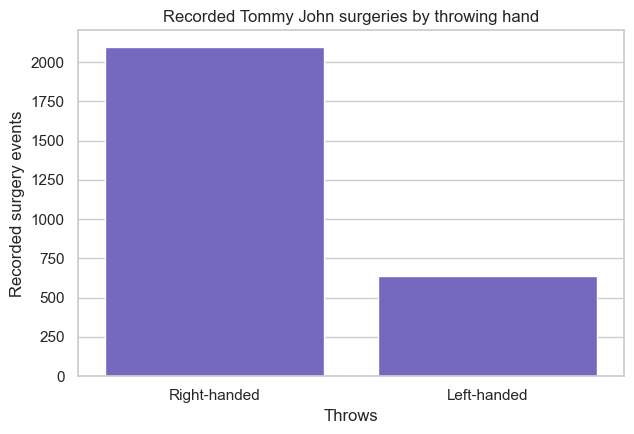

In [9]:
hand = eda["throws"].astype("string").str.strip().str.upper()
hand_counts = hand[hand.isin(["R", "L"])].value_counts().reindex(["R", "L"], fill_value=0)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
if hand_counts.sum() > 0:
    sns.barplot(x=["Right-handed", "Left-handed"], y=hand_counts.values,
                ax=ax, color="slateblue")
    print("Among recorded R/L surgery cases:",
          f"R={hand_counts['R']/hand_counts.sum():.1%}, L={hand_counts['L']/hand_counts.sum():.1%}")
else:
    ax.text(.5, .5, "No throwing-hand entries", ha="center", transform=ax.transAxes)
ax.set(title="Recorded Tommy John surgeries by throwing hand",
       xlabel="Throws", ylabel="Recorded surgery events")
plt.tight_layout()
plt.show()

The difference in counts may reflect the much larger population of right-handed throwers. Do not conclude one handedness has higher risk unless we add the denominator (all eligible right- and left-handed players).

### Data-quality summary before cleaning

The checks below help answer the assignment's EDA questions about missing values, outliers, duplicates, and variable types. In particular, missing return/recovery times require special treatment. A player may not have returned yet, may never return to the same level, or may simply lack an updated report; these are not interchangeable outcomes.

In [10]:
quality_cols = ["player", "surgery_date", "age", "position", "level", "throws",
                "return_date", "recovery_months"]
summary = pd.DataFrame({
    "nonmissing": eda[quality_cols].notna().sum(),
    "missing": eda[quality_cols].isna().sum(),
    "missing_pct": (100 * eda[quality_cols].isna().mean()).round(1),
    "data_type_after_parsing": eda[quality_cols].dtypes.astype(str)
})
display(summary.sort_values("missing_pct", ascending=False))

print("Age quartiles / extremes:")
display(eda["age"].describe())
print("Recorded recovery-time quartiles / extremes:")
display(eda["recovery_months"].describe())
print("Possible problematic rows for manual review:")
review_mask = (~eda["age"].isna() & ~eda["age"].between(12, 60)) |               (eda["recovery_months"].notna() & ~eda["recovery_months"].between(0.01, 60))
display(eda.loc[review_mask, ["player", "surgery_date", "age", "recovery_months"]].head(12))

,nonmissing,missing,missing_pct,data_type_after_parsing
recovery_months,1382,1363,49.7,float64
return_date,2282,463,16.9,datetime64[ns]
player,2745,0,0.0,object
surgery_date,2745,0,0.0,datetime64[ns]
position,2745,0,0.0,object
age,2745,0,0.0,int64
throws,2745,0,0.0,object
level,2745,0,0.0,object


Age quartiles / extremes:


count    2745.000000
mean       23.293260
std         4.116866
min        13.000000
25%        20.000000
50%        23.000000
75%        26.000000
max        47.000000
Name: age, dtype: float64

Recorded recovery-time quartiles / extremes:


count    1382.000000
mean       18.272793
std         7.715439
min         5.000000
25%        13.000000
50%        16.000000
75%        22.000000
max        72.000000
Name: recovery_months, dtype: float64

Possible problematic rows for manual review:


,player,surgery_date,age,recovery_months
1613,Jose Cisnero,2014-05-28,25,61.0
2146,Ryan Feierabend,2009-03-04,23,64.0
2656,Jose Rijo,1995-08-22,30,72.0


## 2. Data Cleaning and Transformation

Changes motivated by EDA:

1. Standardize column names and text categories (e.g., uppercase `L` / `R` and playing levels).
2. Convert surgery/return dates into proper `datetime` fields, and age/recovery months into numeric values; invalid conversions become missing rather than made-up values.
3. Drop rows without a valid player or surgery date, which are unusable for case-level analysis over time.
4. Remove exact duplicate surgery events based on player ID (when available) or normalized name plus surgery date. Do not drop all repeated player names: repeat surgeries are real possibilities.
5. Mark impossible numeric values as missing, while keeping plausible but unusually long recovery times for review. Excluding genuine outliers could bias the results.
6. Leave missing return/recovery outcomes missing for now. Fill a missing number of months only when a valid same-level return date is supplied, computing the elapsed months directly from the two dates.
7. Add `surgery_year` and a flag describing where recovery information came from. The cleaned CSV is saved for reproducibility.

In [11]:
clean = eda.copy()
starting_rows = len(clean)
clean["player"] = clean["player"].astype("string").str.strip()
for col in ["level", "position", "throws"]:
    clean[col] = clean[col].astype("string").str.strip().str.upper()
    clean[col] = clean[col].replace({"": pd.NA, "NAN": pd.NA, "NONE": pd.NA})

# Keep only cases with an identifiable player and valid surgery date.
clean = clean.loc[clean["player"].notna() & clean["surgery_date"].notna()].copy()
removed_unusable = starting_rows - len(clean)

# These ages are implausible for organized baseball and more likely entry errors.
invalid_age = clean["age"].notna() & ~clean["age"].between(12, 60)
clean.loc[invalid_age, "age"] = np.nan
invalid_recovery = clean["recovery_months"].notna() & (clean["recovery_months"] <= 0)
clean.loc[invalid_recovery, "recovery_months"] = np.nan

# Calculate recovery months from a documented return date only where missing.
valid_elapsed_days = (clean["return_date"] - clean["surgery_date"]).dt.days
can_derive = (clean["recovery_months"].isna() & valid_elapsed_days.gt(0))
clean["recovery_source"] = np.where(clean["recovery_months"].notna(), "reported", "unknown")
clean.loc[can_derive, "recovery_months"] = valid_elapsed_days[can_derive] / 30.4375
clean.loc[can_derive, "recovery_source"] = "derived_from_dates"

# Prefer unique MLBAM ID where present, otherwise use a normalized name.
clean["player_key"] = clean["player"].str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
id_values = clean["mlbamid"].astype("string").str.strip().replace({"": pd.NA, "nan": pd.NA})
clean["case_player_key"] = ("id:" + id_values).fillna("name:" + clean["player_key"])
clean = clean.sort_values(["case_player_key", "surgery_date", "recovery_months"],
                          na_position="last")
pre_dedup_rows = len(clean)
clean = clean.drop_duplicates(subset=["case_player_key", "surgery_date"], keep="first").copy()
removed_duplicate_events = pre_dedup_rows - len(clean)

clean["surgery_year"] = clean["surgery_date"].dt.year.astype("Int64")
clean["age"] = clean["age"].astype("Float64")
clean["recovery_months"] = clean["recovery_months"].astype("Float64")
clean["unusually_long_recovery"] = clean["recovery_months"].gt(60).fillna(False)

print(f"Starting records: {starting_rows:,}")
print(f"Dropped records without identifiable player/date: {removed_unusable:,}")
print(f"Removed duplicate surgery events: {removed_duplicate_events:,}")
print(f"Ages converted to missing after anomaly check: {int(invalid_age.sum()):,}")
print(f"Nonpositive recovery values changed to missing: {int(invalid_recovery.sum()):,}")
print(f"Recovery times derived from known return dates: {int(can_derive.sum()):,}")
print(f"Long recovery times (>60 months) flagged for review: {int(clean['unusually_long_recovery'].sum()):,}")
print(f"Cleaned records: {len(clean):,}")

display(clean[["player", "surgery_date", "age", "level", "throws",
               "recovery_months", "recovery_source", "surgery_year"]].head(10))
OUTPUT_CSV = DATA_DIR / "tj_surgeries_cleaned.csv"
clean.to_csv(OUTPUT_CSV, index=False)
print("Saved:", OUTPUT_CSV)

Starting records: 2,745
Dropped records without identifiable player/date: 0
Removed duplicate surgery events: 0
Ages converted to missing after anomaly check: 0
Nonpositive recovery values changed to missing: 0
Recovery times derived from known return dates: 899
Long recovery times (>60 months) flagged for review: 45
Cleaned records: 2,745


,player,surgery_date,age,level,throws,recovery_months,recovery_source,surgery_year
2736,Don Aase,1982-10-18,27.0,MLB,R,20.0,reported,1982
2681,Scott Aldred,1993-01-01,25.0,MLB,L,39.030801,derived_from_dates,1993
2375,Carlos Almanzar,2005-05-11,31.0,MLB,R,<NA>,unknown,2005
2314,Carlos Almanzar,2006-07-01,32.0,AAA,R,<NA>,unknown,2006
2703,Jose Alvarez,1990-08-23,34.0,MLB,R,<NA>,unknown,1990
2090,Joe Biagini,2010-01-01,20.0,COLL,R,27.23614,derived_from_dates,2010
2360,Brian Anderson,2005-07-21,33.0,MLB,L,<NA>,unknown,2005
2311,Brian Anderson,2006-07-14,34.0,MLB,L,<NA>,unknown,2006
2718,Brad Arnsberg,1988-04-01,24.0,MLB,R,12.0,reported,1988
2654,Rene Arocha,1995-10-08,29.0,MLB,R,19.0,reported,1995


Saved: data\tj_surgeries_cleaned.csv


### Post-cleaning checks and updated observations

Print exact descriptive findings from the cleaned records. These numbers update if the source data is refreshed. Avoid making causal or medical claims from case-only data.

In [12]:
full_years = clean.loc[clean["surgery_year"].between(2000, 2025)]
annual_clean = full_years.groupby("surgery_year").size().sort_index()
if not annual_clean.empty:
    print(f"2000–2025: {len(full_years):,} documented surgery events")
    print(f"Peak recorded year: {int(annual_clean.idxmax())}, "
          f"{int(annual_clean.max())} events")
print("2026 events currently recorded (partial year):",
      int(clean["surgery_year"].eq(2026).sum()))
print("Age median:", clean["age"].median())
print("Share with reported/derived same-level recovery times:",
      f"{clean['recovery_months'].notna().mean():.1%}")
known_returns = clean.loc[clean["recovery_months"].notna()]
if not known_returns.empty:
    print(f"Median documented same-level recovery: "
          f"{known_returns['recovery_months'].median():.1f} months "
          f"(n={len(known_returns):,}; selected subset)")

print("Additional missing-value rate after cleaning:")
display((clean[["age", "level", "throws", "recovery_months"]].isna()
         .mean().mul(100).round(1).rename("Missing %").to_frame()))

2000–2025: 2,554 documented surgery events
Peak recorded year: 2021, 176 events
2026 events currently recorded (partial year): 44
Age median: 23.0
Share with reported/derived same-level recovery times: 83.1%
Median documented same-level recovery: 19.0 months (n=2,281; selected subset)
Additional missing-value rate after cleaning:


,Missing %
age,0.0
level,0.0
throws,0.0
recovery_months,16.9


## 3. Machine Learning Plan

### Proposed model and prediction target

I plan to start with a supervised regression model predicting the number of months to a documented same-level return after Tommy John surgery. Input features would include age at surgery, throwing hand, position, competition level, and surgery year. These are variables known on or before the surgery date; I will **not** use return dates or any information from after surgery as predictors.

- Baseline: `DummyRegressor(strategy="median")` to measure how well a simple constant prediction performs.
- Initial model linear regression or regularized Ridge regression with one-hot encoded categorical variables.
- Comparison: random forest regression to detect possible nonlinear relationships.
- Evaluation:mean absolute error (MAE) in months, alongside the baseline. Group by player when splitting repeated surgeries, and consider an out-of-time test (older surgery years for training, more recent completed follow-up years for testing).

### Anticipated challenges and solutions

Missing recovery outcomes / selection bias: A blank return date does not imply that a player failed to return. Training only on recorded returns means predictions apply to documented returners, not all surgery patients. I will explicitly state this limitation and examine missingness by surgery year and level. The more recent surgeries must be excluded from time-to-return training because they have had less follow-up time.

Small or unbalanced subsets: Certain levels and non-pitcher positions may have few cases. I will combine rare categories if necessary, evaluate error by subgroup, and avoid overconfident conclusions.

Duplicates / repeat surgery and leakage: I will deduplicate records for the same surgery but preserve separate surgeries. I will split data in a way that avoids putting the same player's multiple records into both training and test sets.

Limited prediction strength: This data does not include mechanics, workload, velocity, injury severity, medical treatment, or rehabilitation details. Thus even a working model might perform poorly. I will compare against the median baseline and report the limitations rather than claiming the model explains why injuries happen.

Missing predictor values / outliers: Numeric features will be imputed using training-only medians; categorical values will receive an `Unknown` category during pipeline preprocessing. Plausible extreme recovery times will be checked and model sensitivity to them will be reported.

Alternative if the regression data are too incomplete: Keep the project descriptive or model a more restricted target, such as documented recovery time ≥18 months among players who returned to the same level, with appropriate class balance and selection-bias warnings. I will not treat nonreturners or missing follow-up as negative class examples.

In [ ]:
model_candidate = clean.loc[
    clean["surgery_year"].between(2000, 2022) &
    clean["recovery_months"].notna() &
    clean["recovery_months"].gt(0)
].copy()
features = ["age", "throws", "position", "level", "surgery_year"]
print("Candidate records for same-level return-time regression:", len(model_candidate))
print("Candidate target median, in months:", model_candidate["recovery_months"].median())
print("Predictor missingness in candidate pool:")
display(model_candidate[features].isna().mean().mul(100).round(1))
print("Number of separate players in candidate pool:", model_candidate["case_player_key"].nunique())
print("Note: this cohort excludes players without documented recovery outcomes; it is selected.")

Candidate records for same-level return-time regression: 1903
Candidate target median, in months: 19.515400410677618
Predictor missingness in candidate pool:


age             0.0
throws          0.0
position        0.0
level           0.0
surgery_year    0.0
dtype: float64

Number of separate players in candidate pool: 1819
Note: this cohort excludes players without documented recovery outcomes; it is selected.


In [ ]:
!jupyter nbconvert --to python source.ipynb